In [1]:
import pandas as pd
df = pd.read_csv("realtime_cdr_fraud_dataset.csv")

In [2]:
df.head()

,caller_id,receiver_id,start_time,duration_sec,call_type,sim_id,device_id,location_origin,country_origin,location_dest,country_dest,is_night_call,transaction_status,fraud_type
0,3211281536,3037163426,2025-05-31 16:09:56,293,local,SIM007367,DEV02445,Kampala,UG,Johannesburg,ZA,0,Genuine,none
1,6322161221,7891405286,2025-05-31 16:09:56,213,international,SIM013788,DEV00050,Cairo,EG,Lagos,NG,0,Genuine,none
2,9817588945,2131701684,2025-05-31 16:09:56,191,international,SIM010409,DEV08742,Lagos,NG,Lagos,NG,0,Genuine,none
3,7187231493,7356618128,2025-05-31 16:09:56,14,international,SIM001431,DEV02109,Nairobi,KE,Addis Ababa,ET,0,Fraudulent,sim_box_fraud
4,3892030047,8530188712,2025-05-31 16:09:56,166,international,SIM015017,DEV07134,Cairo,EG,Addis Ababa,ET,0,Genuine,none


In [3]:
df.tail()

,caller_id,receiver_id,start_time,duration_sec,call_type,sim_id,device_id,location_origin,country_origin,location_dest,country_dest,is_night_call,transaction_status,fraud_type
24538,2265924499,1661286099,2025-05-31 16:10:03,108,local,SIM_FAKE_464,DEV06868,Lagos,NG,Cairo,EG,0,Fraudulent,subscription_fraud
24539,8851806133,8416072887,2025-05-31 16:10:03,130,international,SIM_FAKE_618,DEV04379,Kampala,UG,Kampala,UG,0,Fraudulent,subscription_fraud
24540,7393327564,2295408755,2025-05-31 16:10:03,40,international,SIM002680,DEV07218,Cairo,EG,Cairo,EG,0,Fraudulent,sim_box_fraud
24541,3098963009,6094314356,2025-05-31 16:10:03,158,local,SIM003342,DEV07279,Accra,GH,Lagos,NG,0,Genuine,none
24542,1198042236,6654253602,2025-05-31 16:10:03,81,international,SIM008052,DEV03145,Johannesburg,ZA,Lagos,NG,0,Genuine,none


In [4]:
df.shape

(24543, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24543 entries, 0 to 24542
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   caller_id           24543 non-null  int64 
 1   receiver_id         24543 non-null  int64 
 2   start_time          24543 non-null  object
 3   duration_sec        24543 non-null  int64 
 4   call_type           24543 non-null  object
 5   sim_id              24543 non-null  object
 6   device_id           24543 non-null  object
 7   location_origin     24543 non-null  object
 8   country_origin      24543 non-null  object
 9   location_dest       24543 non-null  object
 10  country_dest        24543 non-null  object
 11  is_night_call       24543 non-null  int64 
 12  transaction_status  24543 non-null  object
 13  fraud_type          24543 non-null  object
dtypes: int64(4), object(10)
memory usage: 2.6+ MB


In [6]:
df.describe()

,caller_id,receiver_id,duration_sec,is_night_call
count,2.454300e+04,2.454300e+04,24543.000000,24543.0
mean,5.515138e+09,5.491730e+09,163.143422,0.0
std,2.603057e+09,2.591013e+09,176.773624,0.0
min,1.000161e+09,1.000003e+09,10.000000,0.0
25%,3.252308e+09,3.267226e+09,38.000000,0.0
50%,5.517365e+09,5.465968e+09,103.000000,0.0
75%,7.763494e+09,7.726502e+09,226.000000,0.0
max,9.999999e+09,9.999741e+09,1840.000000,0.0


In [7]:
df['fraud_type'].value_counts()

,count
fraud_type,
none,12223
sim_box_fraud,3096
subscription_fraud,3089
random_fraud,3083
call_masking,3052


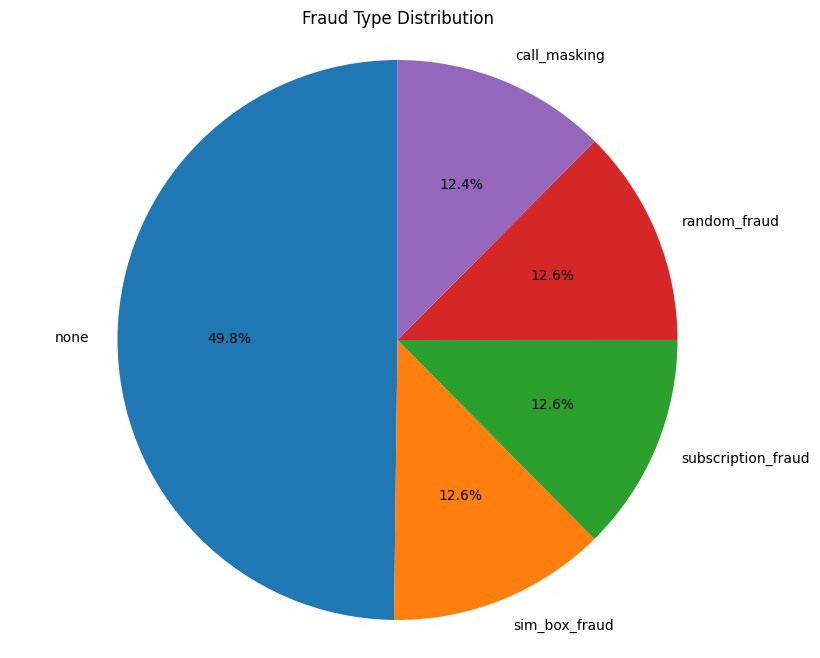

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 8))
fraud_type_counts = df['fraud_type'].value_counts()
wedges, _, _ = plt.pie(fraud_type_counts, labels=fraud_type_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Fraud Type Distribution')
plt.axis('equal')


pie_colors = [wedge.get_facecolor() for wedge in wedges]
pie_chart_color_map = dict(zip(fraud_type_counts.index, pie_colors))

plt.savefig('fraud_type_pie.png')
plt.show()
plt.close()

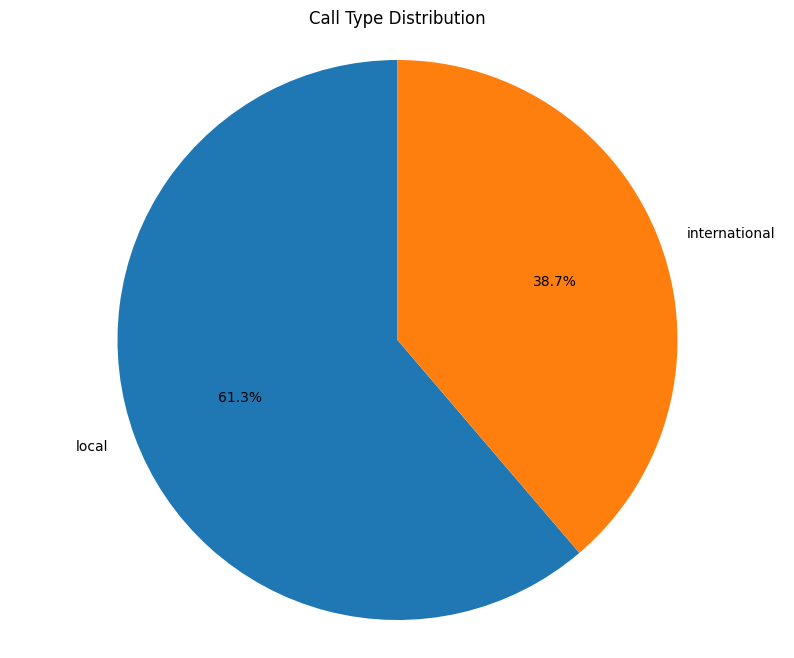

In [9]:
plt.figure(figsize=(10, 8))
call_type_counts = df['call_type'].value_counts()
plt.pie(call_type_counts, labels=call_type_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Call Type Distribution')
plt.axis('equal')
plt.savefig('call_type_pie.png')
plt.show()
plt.close()

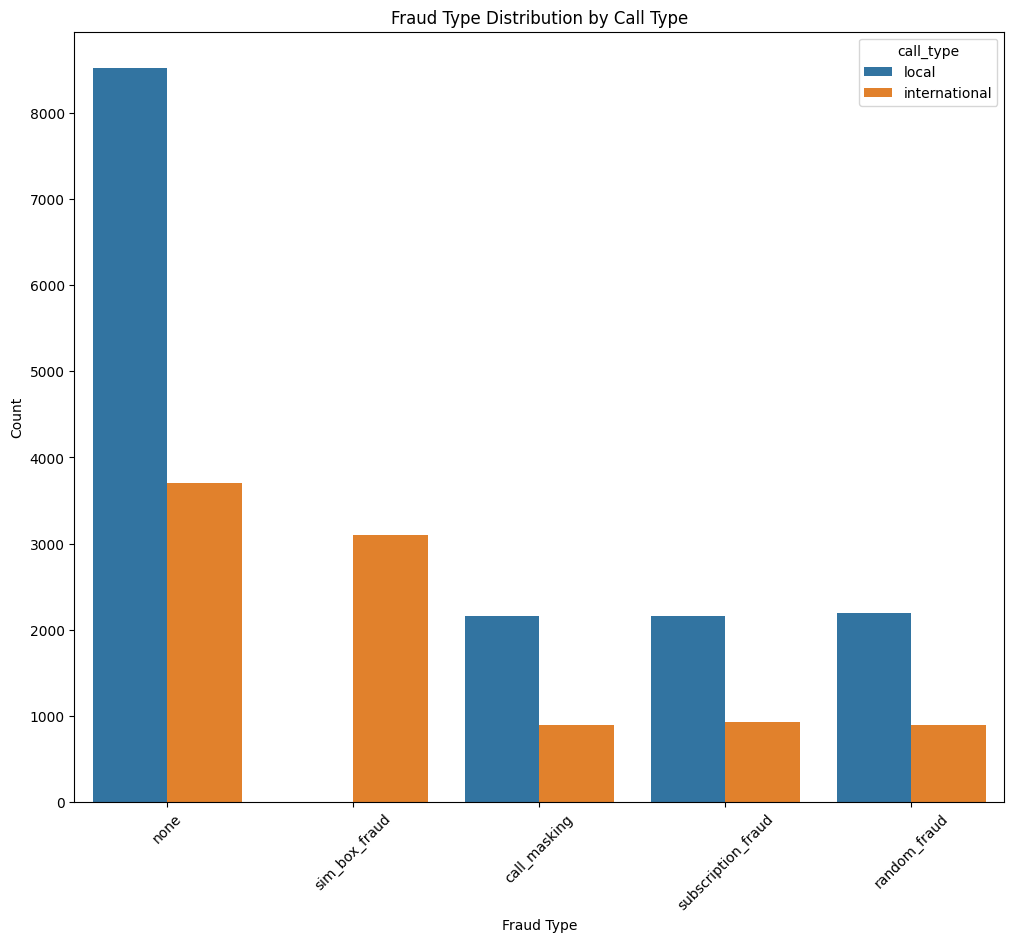

In [10]:
plt.figure(figsize=(12, 10))
sns.countplot(data=df, x='fraud_type', hue='call_type')
plt.title('Fraud Type Distribution by Call Type')
plt.xlabel('Fraud Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.savefig('fraud_type_by_call_type.png')
plt.show()
plt.close()

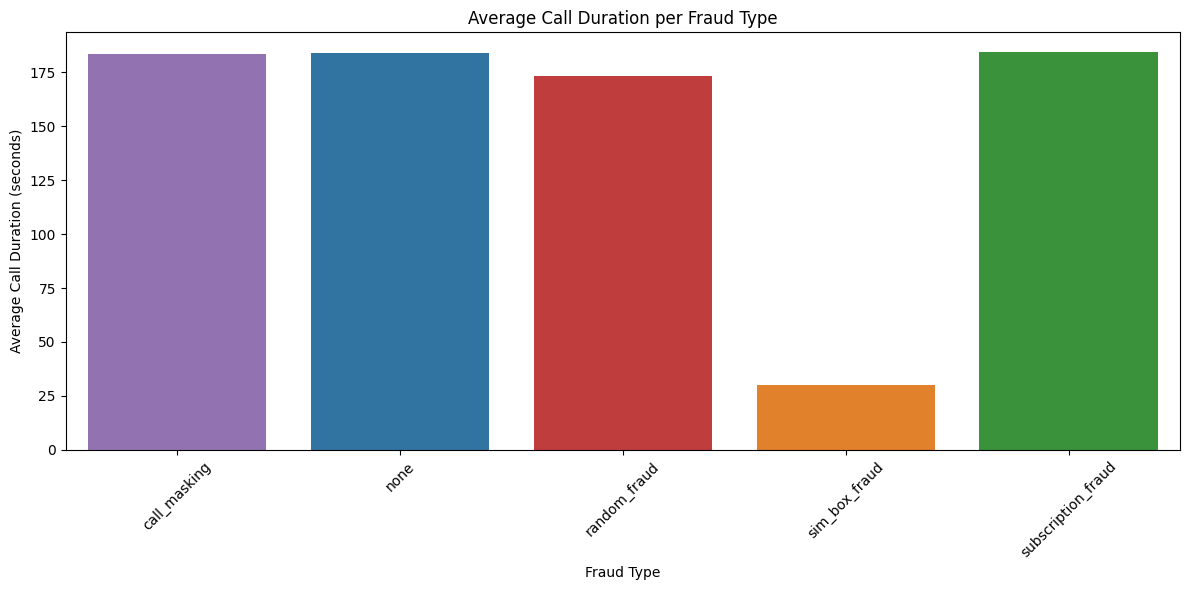

In [11]:
average_duration_per_fraud_type = df.groupby('fraud_type')['duration_sec'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=average_duration_per_fraud_type, x='fraud_type', y='duration_sec', hue='fraud_type', palette=pie_chart_color_map, legend=False)
plt.title('Average Call Duration per Fraud Type')
plt.xlabel('Fraud Type')
plt.ylabel('Average Call Duration (seconds)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('average_call_duration_by_fraud_type.png')
plt.show()
plt.close()

In [12]:
df = df.drop(['start_time','location_origin','country_origin','location_dest','country_dest','is_night_call','transaction_status'], axis=1)
df

,caller_id,receiver_id,duration_sec,call_type,sim_id,device_id,fraud_type
0,3211281536,3037163426,293,local,SIM007367,DEV02445,none
1,6322161221,7891405286,213,international,SIM013788,DEV00050,none
2,9817588945,2131701684,191,international,SIM010409,DEV08742,none
3,7187231493,7356618128,14,international,SIM001431,DEV02109,sim_box_fraud
4,3892030047,8530188712,166,international,SIM015017,DEV07134,none
...,...,...,...,...,...,...,...
24538,2265924499,1661286099,108,local,SIM_FAKE_464,DEV06868,subscription_fraud
24539,8851806133,8416072887,130,international,SIM_FAKE_618,DEV04379,subscription_fraud
24540,7393327564,2295408755,40,international,SIM002680,DEV07218,sim_box_fraud
24541,3098963009,6094314356,158,local,SIM003342,DEV07279,none


In [13]:
df.columns = ['Caller_number', 'Called_number', 'Duration','Call_type','IMSI','IMEI','Fraud_type']
df

,Caller_number,Called_number,Duration,Call_type,IMSI,IMEI,Fraud_type
0,3211281536,3037163426,293,local,SIM007367,DEV02445,none
1,6322161221,7891405286,213,international,SIM013788,DEV00050,none
2,9817588945,2131701684,191,international,SIM010409,DEV08742,none
3,7187231493,7356618128,14,international,SIM001431,DEV02109,sim_box_fraud
4,3892030047,8530188712,166,international,SIM015017,DEV07134,none
...,...,...,...,...,...,...,...
24538,2265924499,1661286099,108,local,SIM_FAKE_464,DEV06868,subscription_fraud
24539,8851806133,8416072887,130,international,SIM_FAKE_618,DEV04379,subscription_fraud
24540,7393327564,2295408755,40,international,SIM002680,DEV07218,sim_box_fraud
24541,3098963009,6094314356,158,local,SIM003342,DEV07279,none


In [14]:
to_drop = df[df['Fraud_type'].isin(['random_fraud', 'call_masking'])].index
df = df.drop(to_drop)
df.shape

(18408, 7)

In [15]:
print(df.isnull().sum())


Caller_number    0
Called_number    0
Duration         0
Call_type        0
IMSI             0
IMEI             0
Fraud_type       0
dtype: int64


In [16]:
df.duplicated().sum()


np.int64(0)

In [17]:
df['Call_traffic'] = df.groupby('Caller_number')['Caller_number'].transform('count')
df.head()

,Caller_number,Called_number,Duration,Call_type,IMSI,IMEI,Fraud_type,Call_traffic
0,3211281536,3037163426,293,local,SIM007367,DEV02445,none,1
1,6322161221,7891405286,213,international,SIM013788,DEV00050,none,1
2,9817588945,2131701684,191,international,SIM010409,DEV08742,none,1
3,7187231493,7356618128,14,international,SIM001431,DEV02109,sim_box_fraud,1
4,3892030047,8530188712,166,international,SIM015017,DEV07134,none,1


In [18]:
df['Call_traffic'].describe()

,Call_traffic
count,18408.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


In [19]:
df['IMSI_call_traffic'] = df.groupby('IMSI')['IMSI'].transform('count')
df.head()

,Caller_number,Called_number,Duration,Call_type,IMSI,IMEI,Fraud_type,Call_traffic,IMSI_call_traffic
0,3211281536,3037163426,293,local,SIM007367,DEV02445,none,1,2
1,6322161221,7891405286,213,international,SIM013788,DEV00050,none,1,3
2,9817588945,2131701684,191,international,SIM010409,DEV08742,none,1,1
3,7187231493,7356618128,14,international,SIM001431,DEV02109,sim_box_fraud,1,2
4,3892030047,8530188712,166,international,SIM015017,DEV07134,none,1,1


In [20]:
df['IMEI_call_traffic'] = df.groupby('IMEI')['IMEI'].transform('count')
df.head()

,Caller_number,Called_number,Duration,Call_type,IMSI,IMEI,Fraud_type,Call_traffic,IMSI_call_traffic,IMEI_call_traffic
0,3211281536,3037163426,293,local,SIM007367,DEV02445,none,1,2,4
1,6322161221,7891405286,213,international,SIM013788,DEV00050,none,1,3,2
2,9817588945,2131701684,191,international,SIM010409,DEV08742,none,1,1,3
3,7187231493,7356618128,14,international,SIM001431,DEV02109,sim_box_fraud,1,2,2
4,3892030047,8530188712,166,international,SIM015017,DEV07134,none,1,1,4


In [21]:
print('IMSI_call_traffic Description:')
display(df['IMSI_call_traffic'].describe())



IMSI_call_traffic Description:


,IMSI_call_traffic
count,18408.000000
mean,2.142112
std,1.340783
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,9.000000


In [22]:
print('\nIMEI_call_traffic Description:')
display(df['IMEI_call_traffic'].describe())


IMEI_call_traffic Description:


,IMEI_call_traffic
count,18408.000000
mean,2.835615
std,1.346854
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,9.000000


In [23]:
df = df.drop(['Caller_number', 'Called_number','Call_traffic' ,'IMSI','IMEI'], axis=1)
df

,Duration,Call_type,Fraud_type,IMSI_call_traffic,IMEI_call_traffic
0,293,local,none,2,4
1,213,international,none,3,2
2,191,international,none,1,3
3,14,international,sim_box_fraud,2,2
4,166,international,none,1,4
...,...,...,...,...,...
24538,108,local,subscription_fraud,6,2
24539,130,international,subscription_fraud,3,4
24540,40,international,sim_box_fraud,1,2
24541,158,local,none,3,2


In [24]:
df['IMSI/IMEI'] = df['IMSI_call_traffic']/df['IMEI_call_traffic']
df

,Duration,Call_type,Fraud_type,IMSI_call_traffic,IMEI_call_traffic,IMSI/IMEI
0,293,local,none,2,4,0.500000
1,213,international,none,3,2,1.500000
2,191,international,none,1,3,0.333333
3,14,international,sim_box_fraud,2,2,1.000000
4,166,international,none,1,4,0.250000
...,...,...,...,...,...,...
24538,108,local,subscription_fraud,6,2,3.000000
24539,130,international,subscription_fraud,3,4,0.750000
24540,40,international,sim_box_fraud,1,2,0.500000
24541,158,local,none,3,2,1.500000


In [25]:
print('IMSI/IMEI Description:')
display(df['IMSI/IMEI'].describe())


IMSI/IMEI Description:


,IMSI/IMEI
count,18408.000000
mean,0.981253
std,0.897826
min,0.111111
25%,0.400000
50%,0.666667
75%,1.000000
max,9.000000


In [26]:
cat_col = [col for col in df.columns if df[col].dtype == 'object']
num_col = [col for col in df.columns if df[col].dtype != 'object']

print('Categorical columns:', cat_col)
print('Numerical columns:', num_col)

Categorical columns: ['Call_type', 'Fraud_type']
Numerical columns: ['Duration', 'IMSI_call_traffic', 'IMEI_call_traffic', 'IMSI/IMEI']


In [27]:
from sklearn.preprocessing import MinMaxScaler



df_encoded = pd.get_dummies(df, columns=['Call_type'], drop_first=False, dtype=int)



scaler = MinMaxScaler()
df_encoded[num_col] = scaler.fit_transform(df_encoded[num_col])

df_encoded

,Duration,Fraud_type,IMSI_call_traffic,IMEI_call_traffic,IMSI/IMEI,Call_type_international,Call_type_local
0,0.154645,none,0.125,0.375,0.043750,0,1
1,0.110929,none,0.250,0.125,0.156250,1,0
2,0.098907,none,0.000,0.250,0.025000,1,0
3,0.002186,sim_box_fraud,0.125,0.125,0.100000,1,0
4,0.085246,none,0.000,0.375,0.015625,1,0
...,...,...,...,...,...,...,...
24538,0.053552,subscription_fraud,0.625,0.125,0.325000,0,1
24539,0.065574,subscription_fraud,0.250,0.375,0.071875,1,0
24540,0.016393,sim_box_fraud,0.000,0.125,0.043750,1,0
24541,0.080874,none,0.250,0.125,0.156250,0,1


In [28]:
from sklearn.preprocessing import LabelEncoder

X = df_encoded.drop("Fraud_type", axis=1)
y = df_encoded["Fraud_type"]


le = LabelEncoder()
y_encoded = le.fit_transform(y)
X.head()





,Duration,IMSI_call_traffic,IMEI_call_traffic,IMSI/IMEI,Call_type_international,Call_type_local
0,0.154645,0.125,0.375,0.043750,0,1
1,0.110929,0.250,0.125,0.156250,1,0
2,0.098907,0.000,0.250,0.025000,1,0
3,0.002186,0.125,0.125,0.100000,1,0
4,0.085246,0.000,0.375,0.015625,1,0


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded)

In [30]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_features='sqrt',
    max_depth=6,
    max_leaf_nodes=6,
)
model.fit(X_train, y_train)
y_pred1 = model.predict(X_test)

In [31]:
import xgboost as xgb
model = xgb.XGBClassifier(
    random_state=42,
    objective='multi:softmax',
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss'
)
model.fit(X_train, y_train)
y_pred2 = model.predict(X_test)


In [32]:
from sklearn.metrics import classification_report
print(classification_report(y_pred1, y_test))

              precision    recall  f1-score   support

           0       0.91      0.89      0.90      3751
           1       0.98      0.76      0.86      1204
           2       0.50      0.82      0.62       568

    accuracy                           0.85      5523
   macro avg       0.80      0.82      0.79      5523
weighted avg       0.88      0.85      0.86      5523



In [33]:
print(classification_report(y_pred2, y_test))

              precision    recall  f1-score   support

           0       0.92      0.89      0.91      3755
           1       0.96      0.79      0.87      1128
           2       0.56      0.80      0.66       640

    accuracy                           0.86      5523
   macro avg       0.81      0.83      0.81      5523
weighted avg       0.88      0.86      0.87      5523

